# Imports & environment

In [1]:
from pathlib import Path
import random
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO
from IPython.display import display
from tqdm.auto import tqdm

In [2]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

print("PyTorch:", torch.__version__)

GPU: NVIDIA GeForce GTX 1650
PyTorch: 2.7.1+cu128


In [3]:
PROJECT_DIR = Path.cwd().parent

DATA_YAML = PROJECT_DIR / "dataset" / "processed" / "data.yaml"

VAL_MANIFEST = (
    PROJECT_DIR
    / "dataset"
    / "processed"
    / "manifests"
    / "val.txt"
)

FINETUNED_CHECKPOINT = (
    PROJECT_DIR
    / "outputs"
    / "yolo11n_bdd100k"
    / "weights"
    / "best.pt"
)

PRETRAINED_CHECKPOINT = (
    PROJECT_DIR
    / "outputs"
    / "yolo11n_bdd100k_classification"
    / "weights"
    / "best.pt"
)

EVALUATION_DIR = PROJECT_DIR / "evaluation_outputs"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

# Dataset configuration

In [4]:
with open(DATA_YAML, "r", encoding="utf-8") as file:
    DATA_CONFIG = yaml.safe_load(file)

class_names = DATA_CONFIG["names"]

print("Number of classes:", len(class_names))
print("Class mapping:")

CLASS_NAMES = {i:j for i,j in enumerate(class_names)}

for class_id, class_name in CLASS_NAMES.items():
    print(f"{class_id}: {class_name}")

Number of classes: 10
Class mapping:
0: car
1: traffic sign
2: traffic light
3: person
4: truck
5: bus
6: bike
7: rider
8: motor
9: train


In [5]:
with open(VAL_MANIFEST, "r", encoding="utf-8") as file:
    VAL_IMAGES = [
        line.strip()
        for line in file
        if line.strip()
    ]

print("Validation images:", len(VAL_IMAGES))
print("First image:", VAL_IMAGES[0])

Validation images: 10000
First image: Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\b1c66a42-6f7d68ca.jpg


# Load both models

In [6]:
PRETRAINED_MODEL = YOLO(str(PRETRAINED_CHECKPOINT))

print("Pretrained model loaded")
print("Pretrained classes:", PRETRAINED_MODEL.names)

Pretrained model loaded
Pretrained classes: {0: 'car', 1: 'traffic sign', 2: 'traffic light', 3: 'person', 4: 'truck', 5: 'bus', 6: 'bike', 7: 'rider', 8: 'motor', 9: 'train'}


In [7]:
FINETUNED_MODEL = YOLO(str(FINETUNED_CHECKPOINT))

print("Fine-tuned model loaded")
print("Fine-tuned classes:", FINETUNED_MODEL.names)

Fine-tuned model loaded
Fine-tuned classes: {0: 'car', 1: 'traffic sign', 2: 'traffic light', 3: 'person', 4: 'truck', 5: 'bus', 6: 'bike', 7: 'rider', 8: 'motor', 9: 'train'}


# Evaluation

In [8]:
# Evaluation configuration

IMAGE_SIZE = 640
BATCH_SIZE = 8
WORKERS = 2
DEVICE = 0 if torch.cuda.is_available() else "cpu"


print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Workers:", WORKERS)
print("Device:", DEVICE)

Image size: 640
Batch size: 8
Workers: 2
Device: 0


In [9]:
assert FINETUNED_CHECKPOINT.exists(), "best.pt was not found. Check that training completed at least one validation epoch."

best_model = YOLO(str(FINETUNED_CHECKPOINT))

metrics = best_model.val(
    data=str(DATA_YAML),
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    device=DEVICE,
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.194  Python-3.10.11 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.3±0.2 ms, read: 131.5±17.6 MB/s, size: 58.8 KB)
val: Scanning Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\labels\val.cache... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1250/1250 8.8it/s 2:210.1sss
                   all      10000     185526      0.593       0.33      0.348      0.186
                   car       9879     102506      0.635      0.629      0.657      0.388
          traffic sign       8221      34908      0.573      0.412      0.433      0.207
         traffic light       5653      26885      0.472      0.421      0.381      0.126
                person       3220      13262    

In [10]:
FINETUNED_METRICS = {
    "Model": "YOLO11n Fine-tuned (BDD100K)",
    "Precision": metrics.box.mp,
    "Recall": metrics.box.mr,
    "mAP50": metrics.box.map50,
    "mAP50-95": metrics.box.map
}

FINETUNED_METRICS

{'Model': 'YOLO11n Fine-tuned (BDD100K)',
 'Precision': np.float64(0.5928045389494367),
 'Recall': np.float64(0.3303721675555694),
 'mAP50': np.float64(0.3476495835905443),
 'mAP50-95': np.float64(0.1856877868591038)}

In [11]:
class_results = []

for class_id, class_name in CLASS_NAMES.items():
    class_results.append({
        "Class ID": class_id,
        "Class": class_name,
        "Precision": metrics.box.p[class_id],
        "Recall": metrics.box.r[class_id],
        "mAP50": metrics.box.ap50[class_id],
        "mAP50-95": metrics.box.ap[class_id]
    })

FINETUNED_CLASS_RESULTS = pd.DataFrame(class_results)

display(
    FINETUNED_CLASS_RESULTS.round(4)
)

,Class ID,Class,Precision,Recall,mAP50,mAP50-95
0,0,car,0.6351,0.6289,0.6573,0.3876
1,1,traffic sign,0.5734,0.4123,0.4328,0.2066
2,2,traffic light,0.4724,0.4210,0.3814,0.1256
3,3,person,0.5520,0.4065,0.4304,0.1934
4,4,truck,0.5701,0.4130,0.4527,0.3117
5,5,bus,0.5220,0.4164,0.4307,0.3251
6,6,bike,0.5104,0.2125,0.2359,0.1038
7,7,rider,0.5128,0.2250,0.2440,0.1086
8,8,motor,0.5799,0.1681,0.2113,0.0946
9,9,train,1.0000,0.0000,0.0000,0.0000


In [12]:
FINETUNED_CLASS_RESULTS.to_csv(
    EVALUATION_DIR / "finetuned_per_class_metrics.csv",
    index=False
)

pd.DataFrame([FINETUNED_METRICS]).to_csv(
    EVALUATION_DIR / "finetuned_overall_metrics.csv",
    index=False
)

print("Fine-tuned evaluation results saved.")

Fine-tuned evaluation results saved.


# Evaluate the Original Pretrained YOLO11n

In [13]:
assert PRETRAINED_CHECKPOINT.exists(), (
    "Pretrained yolo11n.pt not found in the current directory."
)

pretrained_model = YOLO(str(PRETRAINED_CHECKPOINT))

print("Pretrained YOLO11n loaded successfully.")

Pretrained YOLO11n loaded successfully.


In [14]:
print("Pretrained model loaded successfully.")
print("Model classes:", pretrained_model.names)

Pretrained model loaded successfully.
Model classes: {0: 'car', 1: 'traffic sign', 2: 'traffic light', 3: 'person', 4: 'truck', 5: 'bus', 6: 'bike', 7: 'rider', 8: 'motor', 9: 'train'}


In [15]:
metrics = pretrained_model.val(
    data=str(DATA_YAML),
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    device=DEVICE
)

Ultralytics 8.4.194  Python-3.10.11 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 63.5±15.9 MB/s, size: 62.2 KB)
val: Scanning Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\labels\val.cache... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1250/1250 9.1it/s 2:170.1sss
                   all      10000     185526      0.338      0.159      0.122     0.0632
                   car       9879     102506      0.357      0.419      0.364      0.203
          traffic sign       8221      34908      0.229      0.112     0.0688     0.0315
         traffic light       5653      26885      0.219      0.089     0.0532     0.0172
                person       3220      13262     

In [16]:
PRETRAINED_METRICS = {
    "Model": "YOLO11n Pretrained (COCO)",
    "Precision": metrics.box.mp,
    "Recall": metrics.box.mr,
    "mAP50": metrics.box.map50,
    "mAP50-95": metrics.box.map
}

PRETRAINED_METRICS

{'Model': 'YOLO11n Pretrained (COCO)',
 'Precision': np.float64(0.33756304986538915),
 'Recall': np.float64(0.15851816451382536),
 'mAP50': np.float64(0.12218311372347504),
 'mAP50-95': np.float64(0.06316760999424162)}

In [17]:
class_results = []

for class_id, class_name in CLASS_NAMES.items():
    class_results.append({
        "Class ID": class_id,
        "Class": class_name,
        "Precision": metrics.box.p[class_id],
        "Recall": metrics.box.r[class_id],
        "mAP50": metrics.box.ap50[class_id],
        "mAP50-95": metrics.box.ap[class_id]
    })

PRETRAINED_CLASS_RESULTS = pd.DataFrame(class_results)

display(
    PRETRAINED_CLASS_RESULTS.round(4)
)

,Class ID,Class,Precision,Recall,mAP50,mAP50-95
0,0,car,0.3566,0.4189,0.3643,0.2032
1,1,traffic sign,0.2294,0.1120,0.0688,0.0315
2,2,traffic light,0.2193,0.0890,0.0532,0.0172
3,3,person,0.3446,0.3016,0.2461,0.1096
4,4,truck,0.2447,0.2071,0.1404,0.0888
5,5,bus,0.2476,0.2142,0.1365,0.0983
6,6,bike,0.2980,0.1648,0.1269,0.0486
7,7,rider,0.2613,0.0555,0.0624,0.0258
8,8,motor,0.1739,0.0221,0.0232,0.0086
9,9,train,1.0000,0.0000,0.0000,0.0000


In [18]:
PRETRAINED_CLASS_RESULTS.to_csv(
    EVALUATION_DIR / "pretrained_per_class_metrics.csv",
    index=False
)

pd.DataFrame([PRETRAINED_METRICS]).to_csv(
    EVALUATION_DIR / "pretrained_overall_metrics.csv",
    index=False
)

print("pre-trained evaluation results saved.")

pre-trained evaluation results saved.


# Qualitative Model Comparison

In [19]:
RANDOM_SEED = 42

random.seed(RANDOM_SEED)

RANDOM_VAL_IMAGES = random.sample(VAL_IMAGES, 10)

print("Selected validation images:")
for image_path in RANDOM_VAL_IMAGES:
    print(image_path)

Selected validation images:
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\b63b1c14-f01a2f6b.jpg
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\b2b70230-bad4ff6e.jpg
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\bd50478a-4eb79ba3.jpg
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\bc07d865-b2971089.jpg
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\bb2f678a-af43ed71.jpg
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\b764f1b2-7ce1c79f.jpg
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\b5dd20c5-ed2da652.jpg
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\c7dab685-05c2f1df.

In [20]:
CONF_THRESHOLD = 0.20
IOU_THRESHOLD = 0.40

MAX_DETECTIONS = 200

In [21]:
PRETRAINED_RESULTS = pretrained_model.predict(
    source=RANDOM_VAL_IMAGES,
    imgsz=IMAGE_SIZE,
    conf=CONF_THRESHOLD,
    iou=IOU_THRESHOLD,
    device=DEVICE,
    max_det=MAX_DETECTIONS,
    verbose=False
)

print(f"Pretrained predictions completed: {len(PRETRAINED_RESULTS)} images")

Pretrained predictions completed: 10 images


In [22]:
FINETUNED_RESULTS = best_model.predict(
    source=RANDOM_VAL_IMAGES,
    imgsz=IMAGE_SIZE,
    conf=CONF_THRESHOLD,
    iou=IOU_THRESHOLD,
    device=DEVICE,
    max_det=MAX_DETECTIONS,
    verbose=False
)

print(f"Fine-tuned predictions completed: {len(FINETUNED_RESULTS)} images")

Fine-tuned predictions completed: 10 images


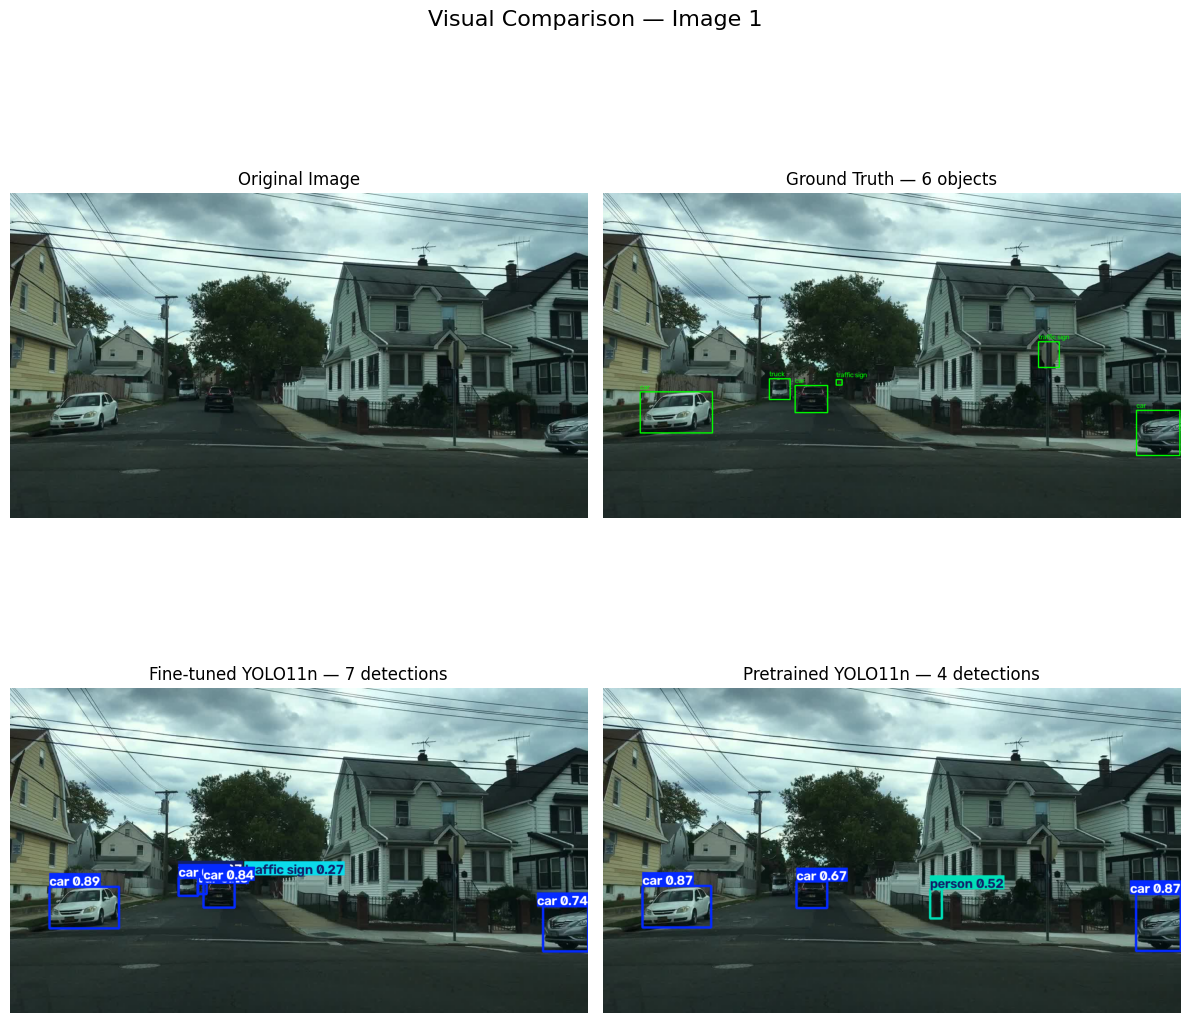

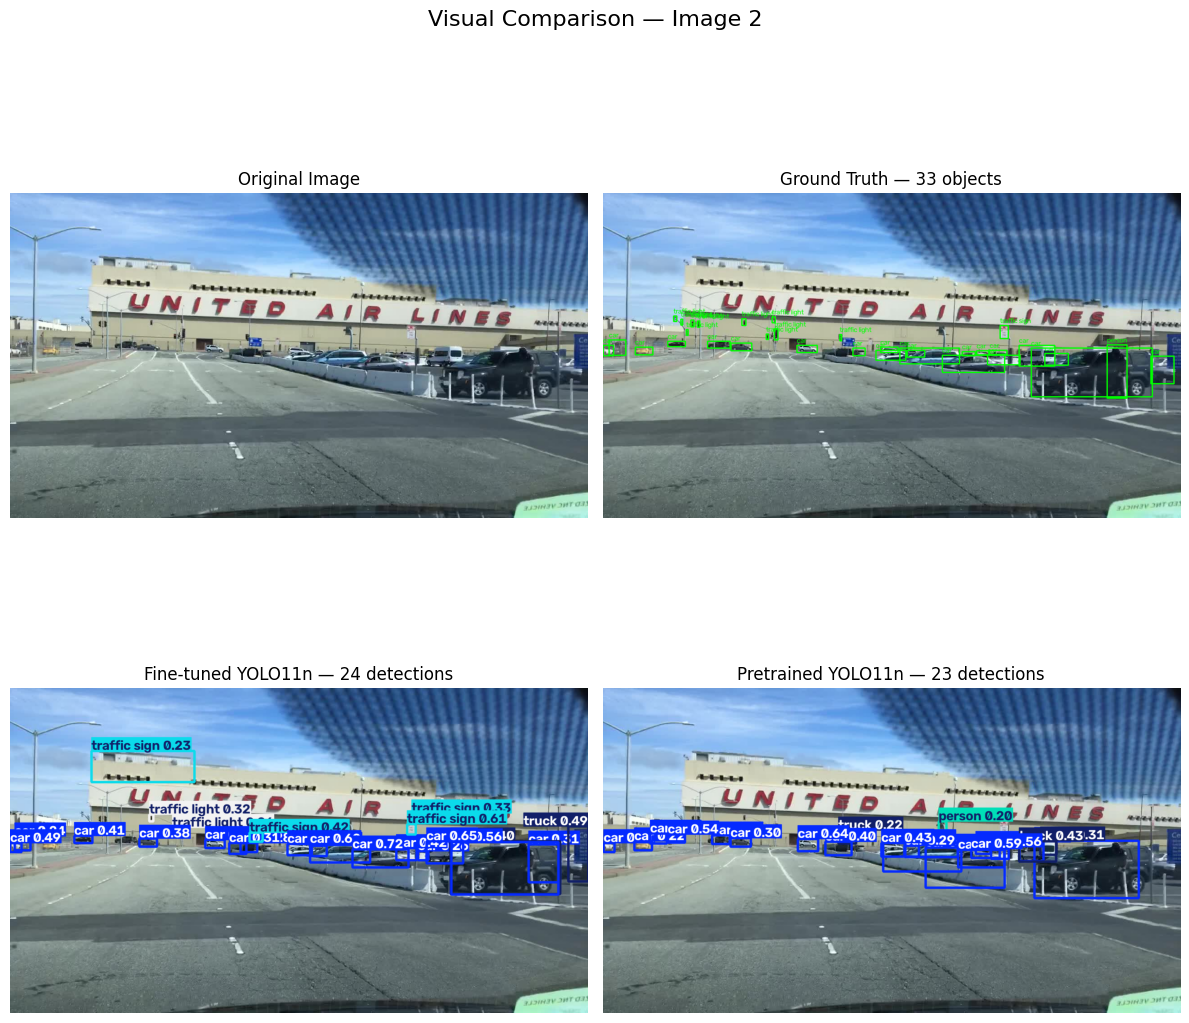

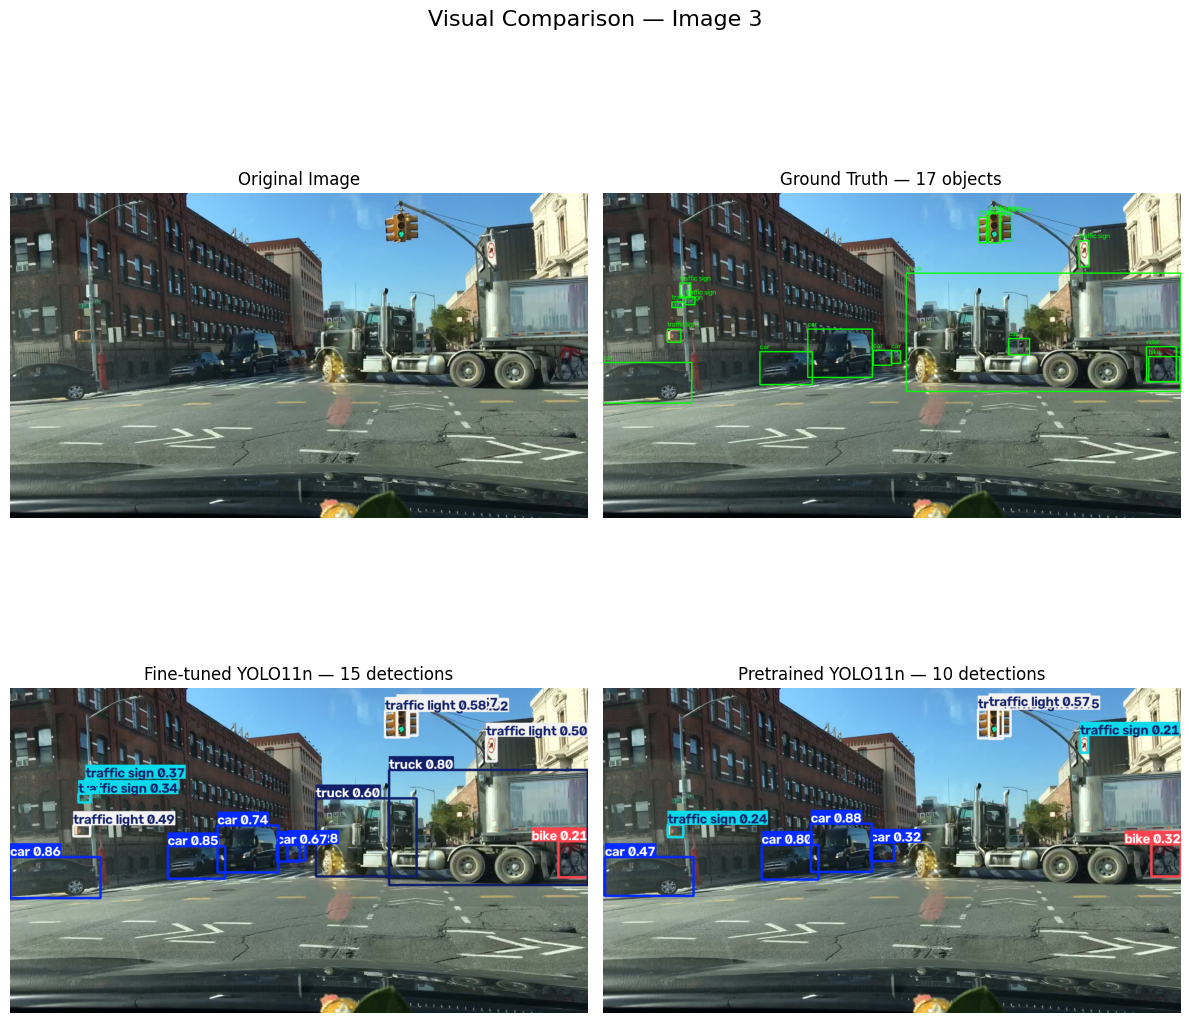

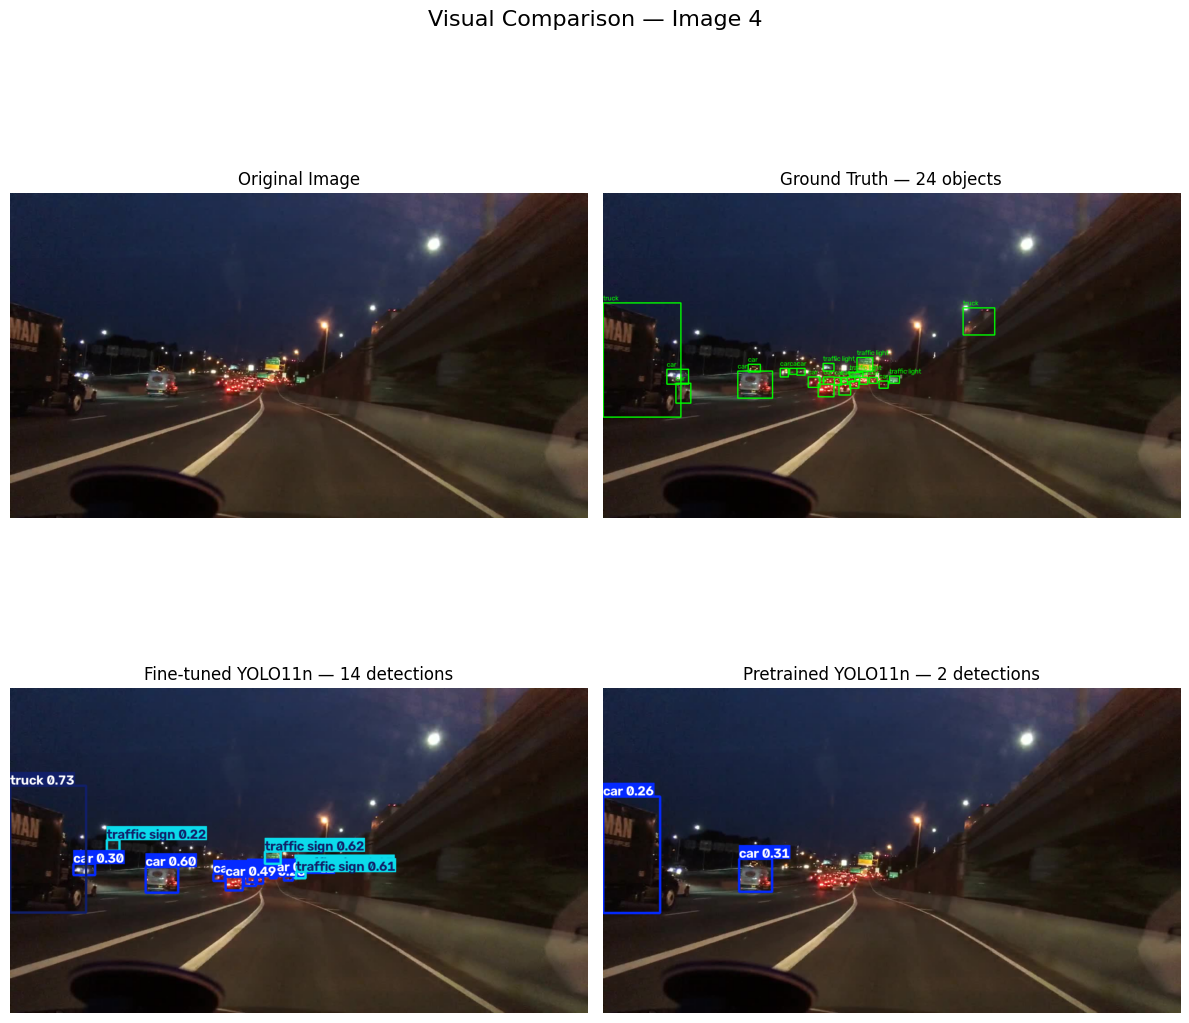

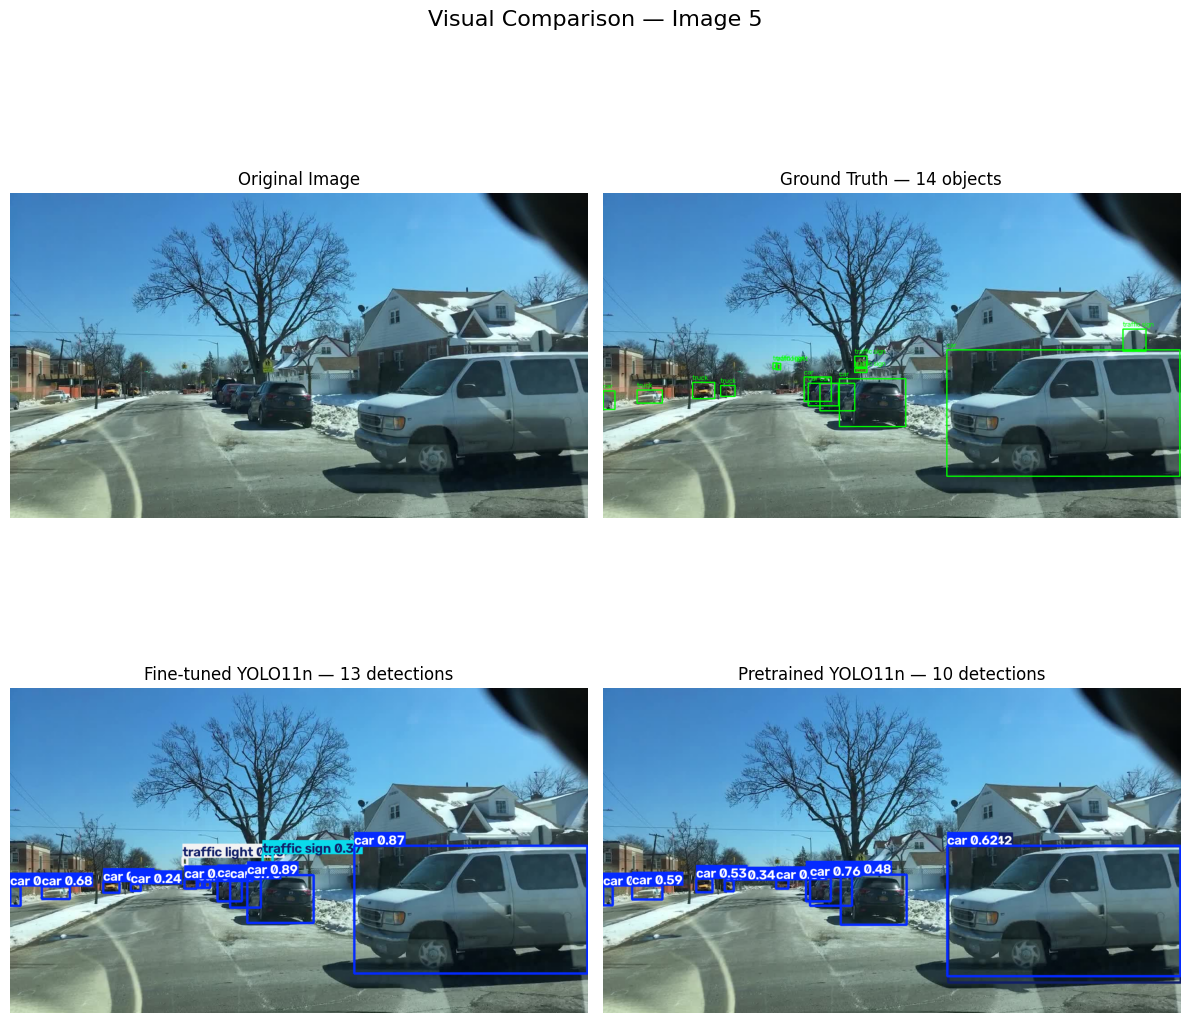

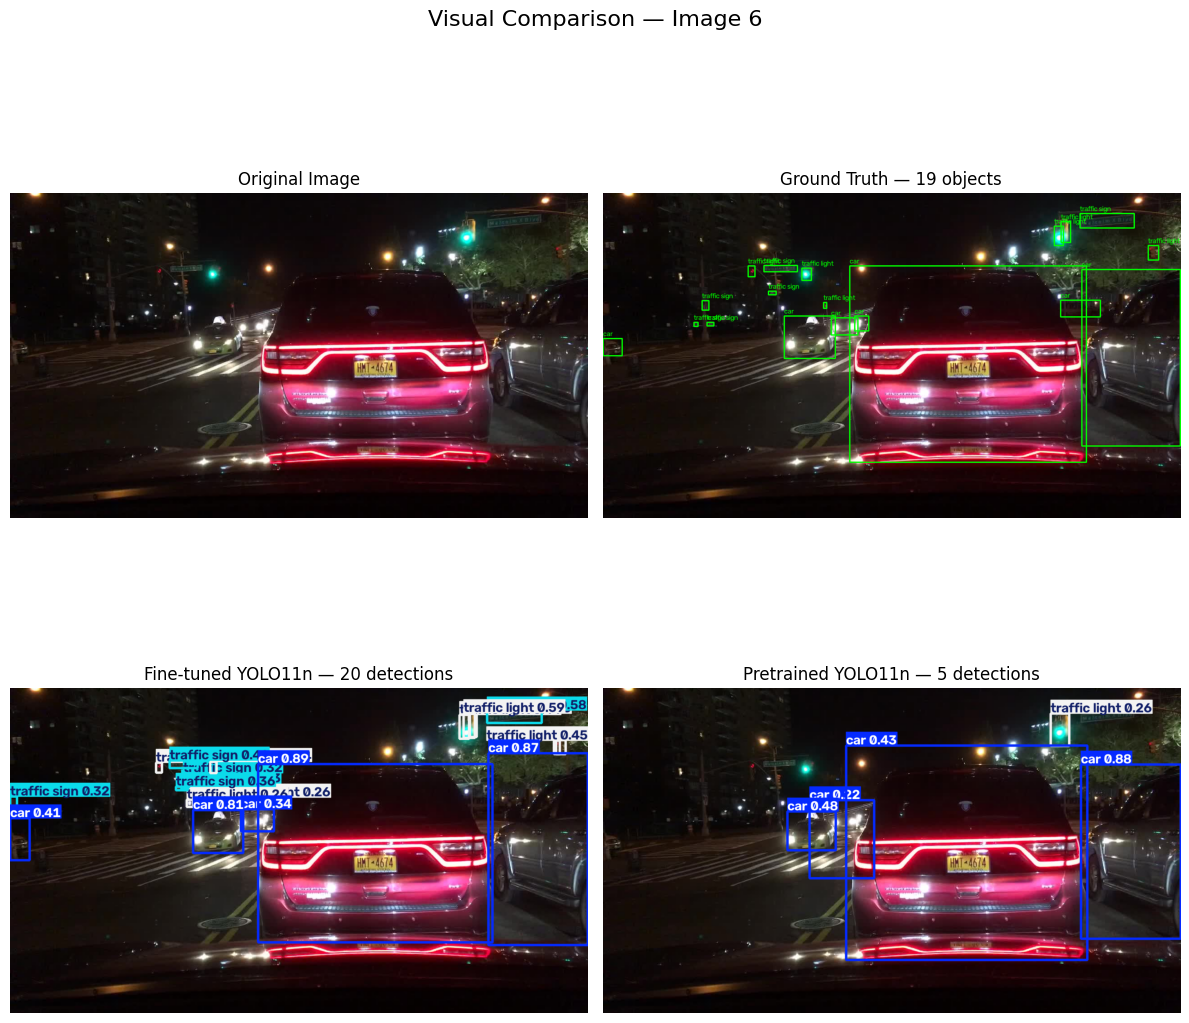

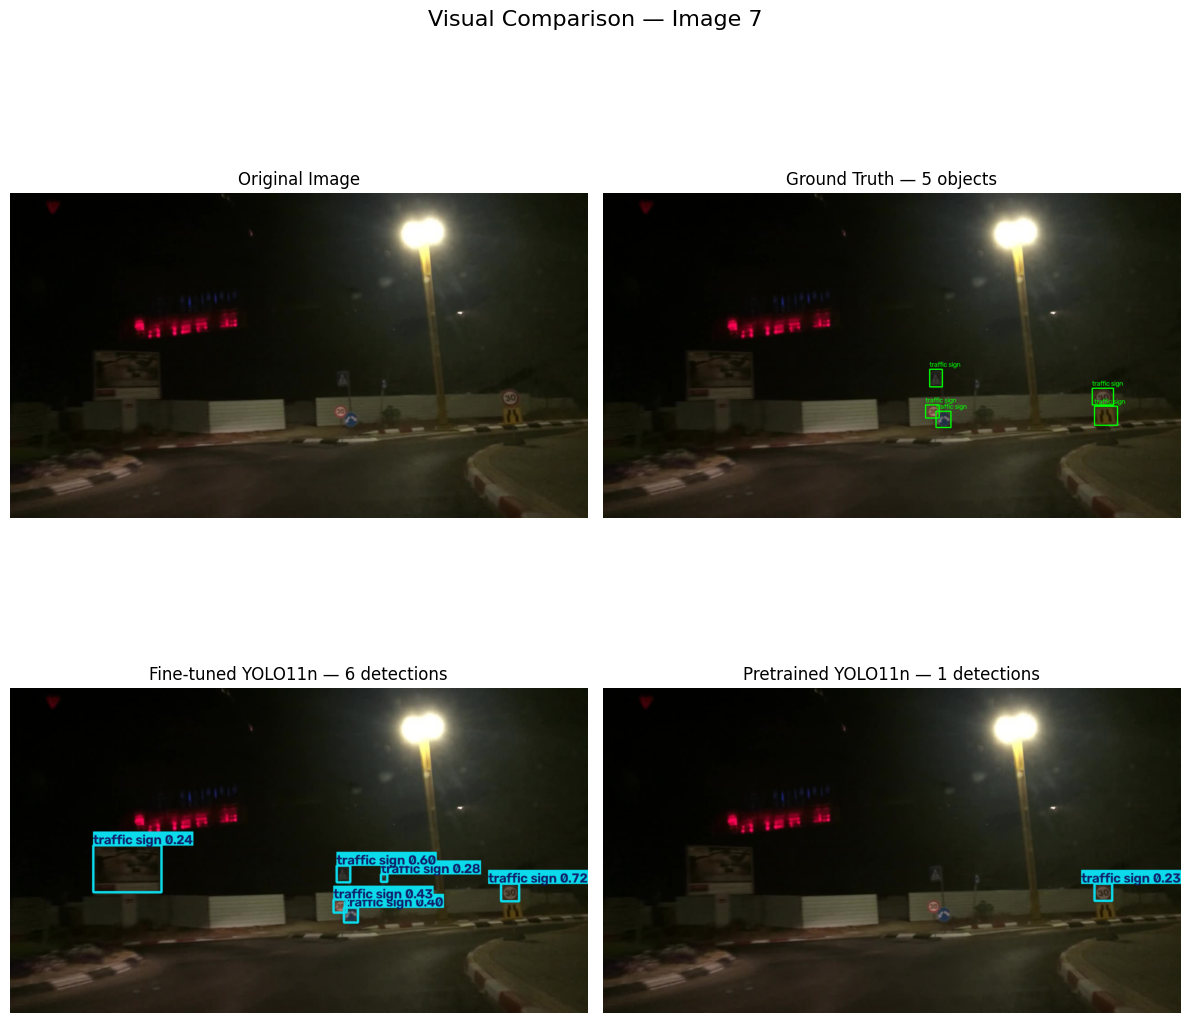

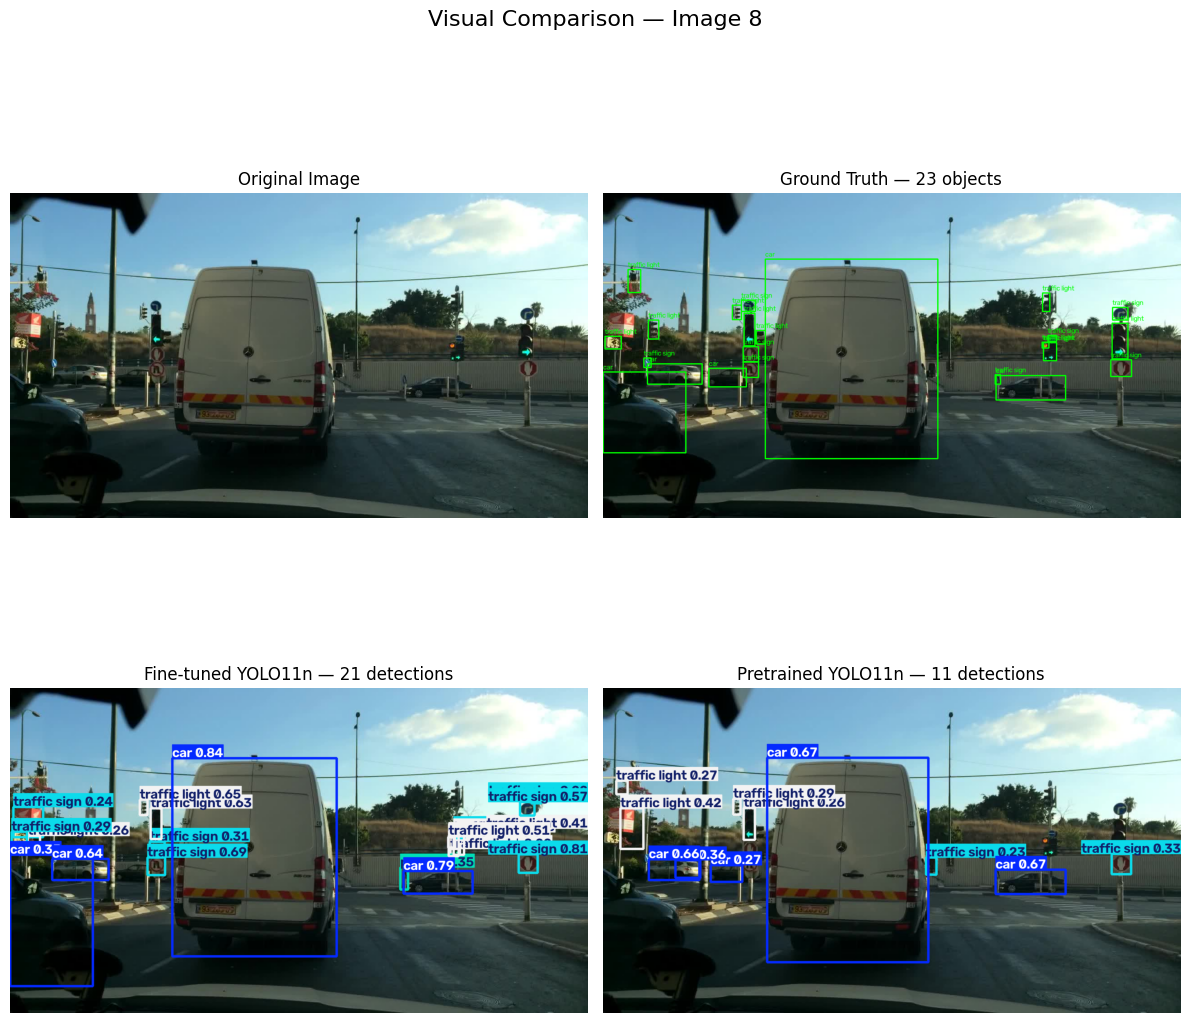

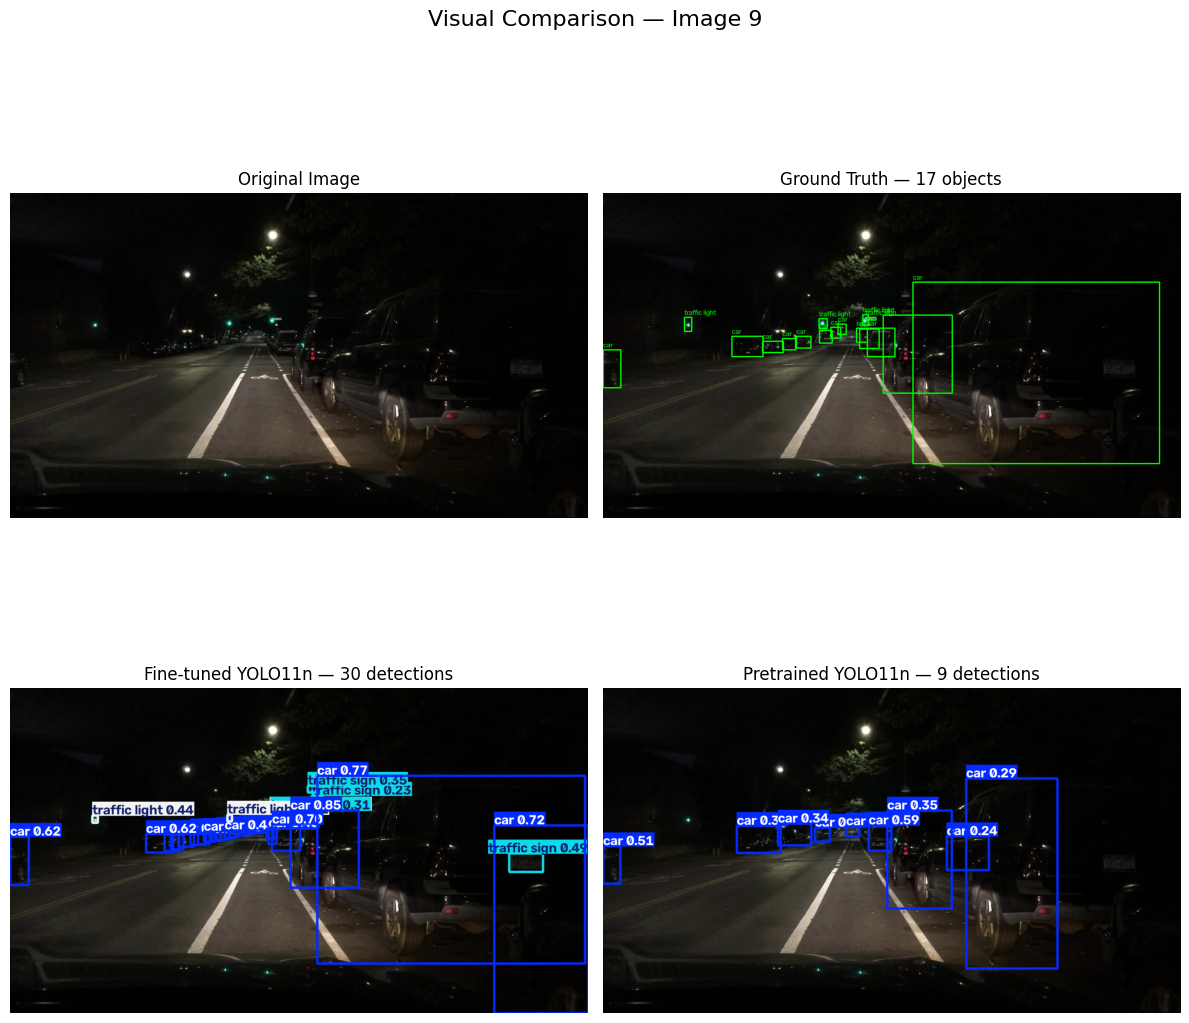

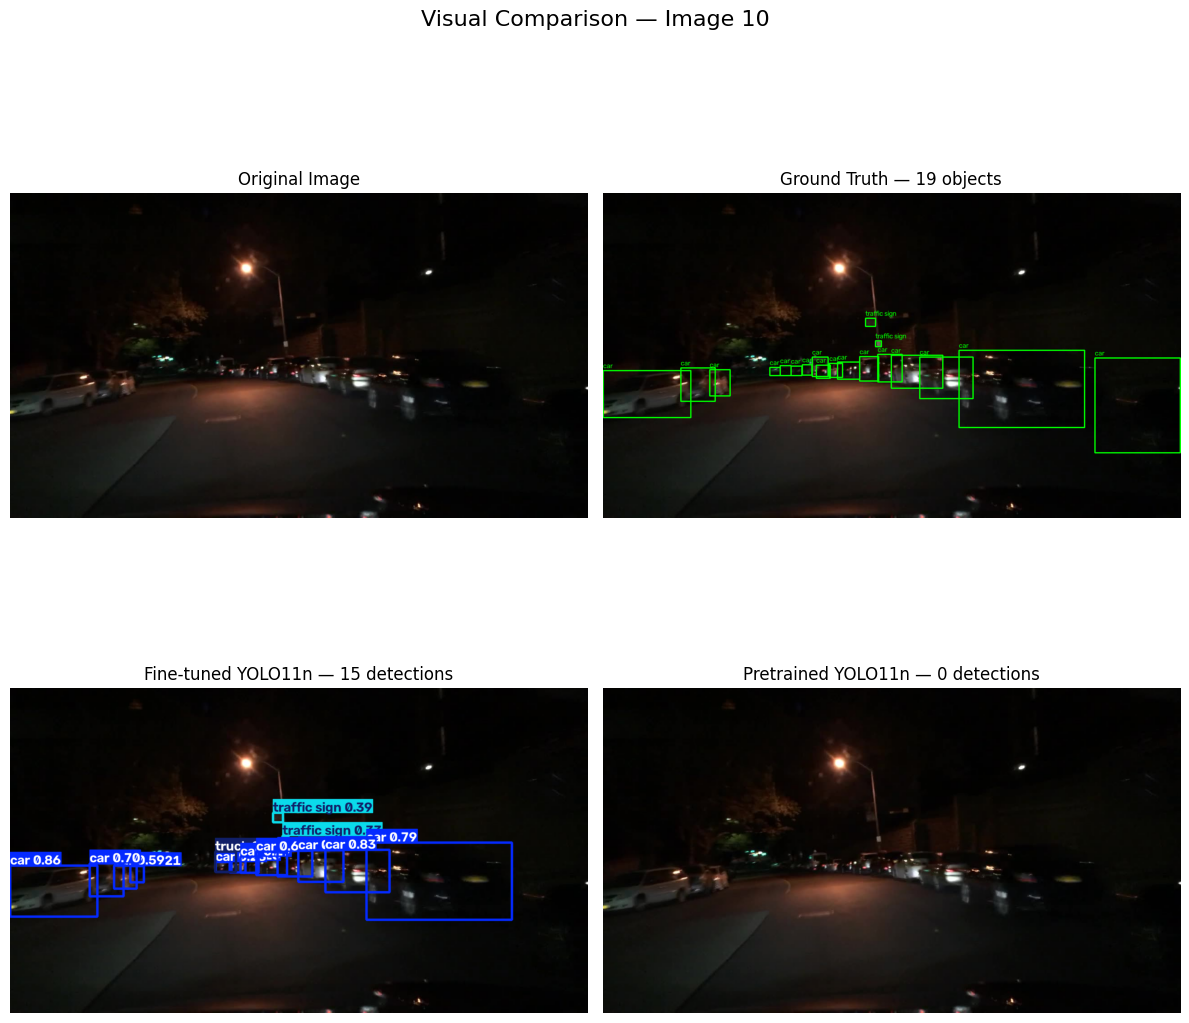

In [23]:
for i, image_path in enumerate(RANDOM_VAL_IMAGES):

    # Original image
    image_path = Path(image_path)
    original_image = cv2.imread(str(image_path))
    original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

    height, width = original_image.shape[:2]

    # Ground-truth label path
    label_path = (
        image_path.parent.parent.parent
        / "labels"
        / image_path.parent.name
        / f"{image_path.stem}.txt"
    )

    ground_truth_image = original_image.copy()

    # Ground-truth object count
    ground_truth_count = 0

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            labels = file.readlines()

        ground_truth_count = sum(1 for line in labels if line.strip())

        for line in labels:
            class_id, x_center, y_center, box_width, box_height = map(
                float, line.split()
            )

            x_center *= width
            y_center *= height
            box_width *= width
            box_height *= height

            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            class_name = CLASS_NAMES[int(class_id)]

            cv2.rectangle(
                ground_truth_image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                ground_truth_image,
                class_name,
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                1
            )

    else:
        print(f"Ground-truth label not found: {label_path}")

    # Pretrained predictions
    pretrained_result = PRETRAINED_RESULTS[i]
    pretrained_count = len(pretrained_result.boxes)

    pretrained_image = cv2.cvtColor(
        pretrained_result.plot(),
        cv2.COLOR_BGR2RGB
    )

    # Fine-tuned predictions
    finetuned_result = FINETUNED_RESULTS[i]
    finetuned_count = len(finetuned_result.boxes)

    finetuned_image = cv2.cvtColor(
        finetuned_result.plot(),
        cv2.COLOR_BGR2RGB
    )

    # Square 2x2 visual comparison
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))

    axes[0, 0].imshow(original_image)
    axes[0, 0].set_title("Original Image")

    axes[0, 1].imshow(ground_truth_image)
    axes[0, 1].set_title(f"Ground Truth — {ground_truth_count} objects")

    axes[1, 0].imshow(finetuned_image)
    axes[1, 0].set_title(f"Fine-tuned YOLO11n — {finetuned_count} detections")

    axes[1, 1].imshow(pretrained_image)
    axes[1, 1].set_title(f"Pretrained YOLO11n — {pretrained_count} detections")

    for ax in axes.flat:
        ax.axis("off")

    plt.suptitle(f"Visual Comparison — Image {i + 1}", fontsize=16)
    plt.tight_layout()
    plt.show()

In [24]:
VISUAL_COMPARISON_DIR = EVALUATION_DIR / "visual_comparisons"
VISUAL_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

for i in range(len(RANDOM_VAL_IMAGES)):
    pretrained_image = cv2.cvtColor(
        PRETRAINED_RESULTS[i].plot(),
        cv2.COLOR_BGR2RGB
    )

    finetuned_image = cv2.cvtColor(
        FINETUNED_RESULTS[i].plot(),
        cv2.COLOR_BGR2RGB
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].imshow(pretrained_image)
    axes[0].set_title("Pretrained YOLO11n")

    axes[1].imshow(finetuned_image)
    axes[1].set_title("Fine-tuned YOLO11n")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()

    fig.savefig(
        VISUAL_COMPARISON_DIR / f"comparison_{i+1:02d}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

print(f"Visual comparisons saved to: {VISUAL_COMPARISON_DIR}")

Visual comparisons saved to: Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\evaluation_outputs\visual_comparisons


In [25]:
import pandas as pd
import numpy as np

# Confidence scores from both models
pretrained_confidences = [
    float(box.conf.item())
    for result in PRETRAINED_RESULTS
    for box in result.boxes
]

finetuned_confidences = [
    float(box.conf.item())
    for result in FINETUNED_RESULTS
    for box in result.boxes
]

# Total ground-truth objects across selected images
total_ground_truth = 0

for image_path in RANDOM_VAL_IMAGES:
    image_path = Path(image_path)

    label_path = (
        image_path.parent.parent.parent
        / "labels"
        / "val"
        / f"{image_path.stem}.txt"
    )

    if label_path.exists():
        with open(label_path, "r") as file:
            total_ground_truth += sum(
                1 for line in file if line.strip()
            )

# Comparison dataframe
comparison_df = pd.DataFrame([
    {
        "Model": "Pretrained YOLO11n",
        "Mean Confidence": np.mean(pretrained_confidences),
        "Median Confidence": np.median(pretrained_confidences),
        "Total Detections": len(pretrained_confidences)
    },
    {
        "Model": "Fine-tuned YOLO11n",
        "Mean Confidence": np.mean(finetuned_confidences),
        "Median Confidence": np.median(finetuned_confidences),
        "Total Detections": len(finetuned_confidences)
    },
    {
        "Model": "Ground Truth",
        "Mean Confidence": "-",
        "Median Confidence": "-",
        "Total Detections": total_ground_truth
    }
]).reset_index(drop=True)

comparison_df

,Model,Mean Confidence,Median Confidence,Total Detections
0,Pretrained YOLO11n,0.411341,0.342548,75
1,Fine-tuned YOLO11n,0.455218,0.389516,165
2,Ground Truth,-,-,177


In [27]:
# 1. BUILD PER-IMAGE COUNT COMPARISON


comparison_rows = []

for i, image_path in enumerate(RANDOM_VAL_IMAGES):

    image_path = Path(image_path)

    # Ground-truth label path
    label_path = (
        image_path.parent.parent.parent
        / "labels"
        / image_path.parent.name
        / f"{image_path.stem}.txt"
    )

    # Ground-truth object count
    ground_truth_count = 0

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            ground_truth_count = sum(
                1 for line in file if line.strip()
            )

    # Prediction counts
    pretrained_count = len(PRETRAINED_RESULTS[i].boxes)
    finetuned_count = len(FINETUNED_RESULTS[i].boxes)

    comparison_rows.append({
        "Image": image_path.name,
        "Ground Truth": ground_truth_count,
        "Pretrained": pretrained_count,
        "Fine-tuned": finetuned_count
    })


# Create dataframe
CLASSWISE_COMPARISON = pd.DataFrame(comparison_rows)

display(CLASSWISE_COMPARISON)



# 2. COUNT-BASED EVALUATION METRICS

def calculate_count_metrics(df, model_column):

    gt = df["Ground Truth"].to_numpy()
    pred = df[model_column].to_numpy()

    tp = np.minimum(gt, pred).sum()
    fp = np.maximum(pred - gt, 0).sum()
    fn = np.maximum(gt - pred, 0).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    return {
        "MAE": np.mean(np.abs(pred - gt)),
        "RMSE": np.sqrt(np.mean((pred - gt) ** 2)),
        "Exact Count Accuracy (%)": np.mean(pred == gt) * 100,
        "Bias": np.mean(pred - gt),
        "Count Precision": precision,
        "Count Recall": recall,
        "Count F1": f1
    }


# 3. COMPARE BOTH MODELS


evaluation_results = []

for model_name, model_column in [
    ("Pretrained YOLO11n", "Pretrained"),
    ("Fine-tuned YOLO11n", "Fine-tuned")
]:

    metrics = calculate_count_metrics(
        CLASSWISE_COMPARISON,
        model_column
    )

    metrics["Model"] = model_name
    evaluation_results.append(metrics)


COUNT_EVALUATION = pd.DataFrame(evaluation_results)

COUNT_EVALUATION = COUNT_EVALUATION[
    [
        "Model",
        "MAE",
        "RMSE",
        "Exact Count Accuracy (%)",
        "Bias",
        "Count Precision",
        "Count Recall",
        "Count F1"
    ]
]

display(COUNT_EVALUATION.round(4))

,Image,Ground Truth,Pretrained,Fine-tuned
0,b63b1c14-f01a2f6b.jpg,6,4,7
1,b2b70230-bad4ff6e.jpg,33,23,24
2,bd50478a-4eb79ba3.jpg,17,10,15
3,bc07d865-b2971089.jpg,24,2,14
4,bb2f678a-af43ed71.jpg,14,10,13
5,b764f1b2-7ce1c79f.jpg,19,5,20
6,b5dd20c5-ed2da652.jpg,5,1,6
7,c7dab685-05c2f1df.jpg,23,11,21
8,b5479087-2e92b8f5.jpg,17,9,30
9,c994e726-d8b6115b.jpg,19,0,15


,Model,MAE,RMSE,Exact Count Accuracy (%),Bias,Count Precision,Count Recall,Count F1
0,Pretrained YOLO11n,10.2,11.9750,0.0,-10.2,1.000,0.4237,0.5952
1,Fine-tuned YOLO11n,4.4,6.1482,0.0,-1.2,0.903,0.8418,0.8713


In [28]:
import numpy as np
import pandas as pd
from pathlib import Path

# ==========================================
# CONFIGURATION
# ==========================================

EVAL_BATCH_SIZE = 8
CONF_THRESHOLD = 0.20
IOU_THRESHOLD = 0.40
MAX_DETECTIONS = 200

# ==========================================
# GROUND-TRUTH COUNTS (ALL 10,000 IMAGES)
# ==========================================

GT_COUNTS = []

for image_path in VAL_IMAGES:

    image_path = Path(image_path)

    label_path = (
        image_path.parent.parent.parent
        / "labels"
        / image_path.parent.name
        / f"{image_path.stem}.txt"
    )

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as f:
            count = sum(1 for line in f if line.strip())
    else:
        count = 0

    GT_COUNTS.append(count)

GT_COUNTS = np.array(GT_COUNTS)


# ==========================================
# BATCH INFERENCE — PRETRAINED MODEL
# ==========================================

PRETRAINED_COUNTS = []

for start in range(0, len(VAL_IMAGES), EVAL_BATCH_SIZE):

    batch_images = VAL_IMAGES[start:start + EVAL_BATCH_SIZE]

    batch_results = pretrained_model.predict(
        source=batch_images,
        imgsz=IMAGE_SIZE,
        conf=CONF_THRESHOLD,
        iou=IOU_THRESHOLD,
        device=DEVICE,
        max_det=MAX_DETECTIONS,
        verbose=False
    )

    PRETRAINED_COUNTS.extend(
        len(result.boxes) for result in batch_results
    )


# ==========================================
# BATCH INFERENCE — FINE-TUNED MODEL
# ==========================================

FINETUNED_COUNTS = []

for start in range(0, len(VAL_IMAGES), EVAL_BATCH_SIZE):

    batch_images = VAL_IMAGES[start:start + EVAL_BATCH_SIZE]

    batch_results = best_model.predict(
        source=batch_images,
        imgsz=IMAGE_SIZE,
        conf=CONF_THRESHOLD,
        iou=IOU_THRESHOLD,
        device=DEVICE,
        max_det=MAX_DETECTIONS,
        verbose=False
    )

    FINETUNED_COUNTS.extend(
        len(result.boxes) for result in batch_results
    )


# ==========================================
# COUNT METRICS
# ==========================================

def calculate_count_metrics(gt, pred):

    gt = np.asarray(gt)
    pred = np.asarray(pred)

    tp = np.minimum(gt, pred).sum()
    fp = np.maximum(pred - gt, 0).sum()
    fn = np.maximum(gt - pred, 0).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    return {
        "MAE": np.mean(np.abs(pred - gt)),
        "RMSE": np.sqrt(np.mean((pred - gt) ** 2)),
        "Exact Count Accuracy (%)": np.mean(pred == gt) * 100,
        "Bias": np.mean(pred - gt),
        "Count Precision": precision,
        "Count Recall": recall,
        "Count F1": f1
    }


# ==========================================
# FINAL COMPARISON TABLE
# ==========================================

final_results = []

for model_name, predictions in [
    ("Pretrained YOLO11n", PRETRAINED_COUNTS),
    ("Fine-tuned YOLO11n", FINETUNED_COUNTS)
]:

    metrics = calculate_count_metrics(
        GT_COUNTS,
        predictions
    )

    metrics["Model"] = model_name
    final_results.append(metrics)


ALL_10000_COUNT_EVALUATION = pd.DataFrame(final_results)

ALL_10000_COUNT_EVALUATION = ALL_10000_COUNT_EVALUATION[
    [
        "Model",
        "MAE",
        "RMSE",
        "Exact Count Accuracy (%)",
        "Bias",
        "Count Precision",
        "Count Recall",
        "Count F1"
    ]
]

ALL_10000_COUNT_EVALUATION.round(4)


,Model,MAE,RMSE,Exact Count Accuracy (%),Bias,Count Precision,Count Recall,Count F1
0,Pretrained YOLO11n,10.9239,13.2771,1.79,-10.8135,0.9929,0.4142,0.5845
1,Fine-tuned YOLO11n,4.8167,6.8156,8.77,-3.8119,0.9659,0.7675,0.8553
